# Round 3 translation scores

Sol monitor runs, plus the Haiku, Gemini, and DeepSeek decoding runs. English scores pair each sender's private intended meaning with section 2 of the decoder report. Language scores compare `swarmish.txt` with section 1. Monolingual scores are computed on each text alone.

BLEU, ROUGE, and cosine run from 0 to 1. BERT perplexity is a sample from `bert-base-uncased`: two 60-word windows, 24 masked tokens each. Color marks the gameplay scenario. Later labels name the decoder and the language it read.


In [22]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.patches import Patch

ROOT = Path.cwd()
if not (ROOT / "logs").exists():
    ROOT = ROOT.parent

ORDER = [
    "baseline_seed1",
    "R01_sol_seed1",
    "R02_sol_seed2",
    "R03_sol_seed3",
    "R04_sol_seed4",
    "R05_sol_seed5",
    "R06_haiku_seed1",
    "R07_gemini_seed1",
    "R08_deepseek_seed1",
]
SCENARIOS = {
    "baseline_seed1": ("sol seed 1 baseline", "#d97706"),
    "R01_sol_seed1": ("sol seed 1", "#1d4e89"),
    "R02_sol_seed2": ("sol seed 2", "#0f7b6c"),
    "R03_sol_seed3": ("sol seed 3", "#b4234a"),
    "R04_sol_seed4": ("sol seed 4", "#6d4c9a"),
    "R05_sol_seed5": ("sol seed 5", "#3f6212"),
    "R06_haiku_seed1": ("haiku seed 1", "#be185d"),
    "R07_gemini_seed1": ("gemini seed 1", "#0284c7"),
    "R08_deepseek_seed1": ("deepseek seed 1", "#a16207"),
}
SOURCE = {
    "R06_haiku_seed1": "haiku",
    "R07_gemini_seed1": "gemini",
    "R08_deepseek_seed1": "deepseek",
}


def decoder_name(model_id):
    name = model_id.rsplit("/", 1)[-1].removeprefix("gpt-6.1-")
    if name == "sol":
        return name
    for token in ("haiku", "gemini", "deepseek"):
        if token in name:
            return token
    return name


def run_name(report):
    summary = json.loads((ROOT / report["monitor_dir"] / "monitor_summary.json").read_text())
    model = decoder_name(summary["model"])
    playthrough = report["playthrough"]
    if playthrough in SOURCE:
        name = f"{model} on {SOURCE[playthrough]}"
    else:
        seed = playthrough.rsplit("seed", 1)[-1]
        name = f"{model} seed {seed}"
        if playthrough.startswith("baseline"):
            name += " baseline"
    condition = "task" if summary["conditions_requested"] == ["task_full"] else "no task"
    return f"{name}, {condition}"


paths = sorted((ROOT / "logs").glob("*/monitor_runs/*_round_3/translation_scores.json"))
paths += sorted((ROOT / "experiments/tangut_200g_250l_200t/decoding").glob("*/raw/*_round_3/translation_scores.json"))
reports = [json.loads(path.read_text()) for path in paths]
reports.sort(key=lambda report: (ORDER.index(report["playthrough"]), report["monitor_dir"]))
scored = [report for report in reports if "english_transcript" in report]
skipped = [report for report in reports if report.get("skipped")]
seen = {}
labels = []
for report in scored:
    name = run_name(report)
    seen[name] = seen.get(name, 0) + 1
    labels.append(name if seen[name] == 1 else f"{name} {seen[name]}")
scenario_colors = [SCENARIOS[report["playthrough"]][1] for report in scored]

plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 10,
})


def paint_labels(ax):
    lookup = dict(zip(labels, scenario_colors))
    for tick in ax.get_yticklabels():
        tick.set_color(lookup[tick.get_text()])


def scenario_legend(figure):
    handles = [Patch(facecolor=color, label=name) for name, color in (SCENARIOS[key] for key in ORDER)]
    figure.legend(handles=handles, loc="outside lower center", ncol=3, frameon=False)


def chart_size(columns):
    height = max(6.5, 0.42 * len(labels) + 1.8)
    return (13 if columns == 2 else 12, height)


def panel(ax, values, title, xlim=None):
    ax.barh(labels, values, color=scenario_colors, height=0.72)
    ax.invert_yaxis()
    ax.set_title(title, loc="left")
    ax.tick_params(axis="y", length=0)
    paint_labels(ax)
    ax.set_xlim(0, xlim)


def grouped(ax, series, title, xlim=None):
    count = len(series)
    height = 0.8 / count
    alphas = {2: (0.35, 1.0), 3: (1.0, 0.62, 0.32)}[count]
    positions = list(range(len(labels)))
    for index, (name, values) in enumerate(series):
        offset = (index - (count - 1) / 2) * height
        ax.barh([pos + offset for pos in positions], values, height=height * 0.92, color=scenario_colors, alpha=alphas[index])
    ax.set_yticks(positions, labels)
    ax.invert_yaxis()
    ax.set_title(title, loc="left")
    ax.tick_params(axis="y", length=0)
    paint_labels(ax)
    ax.legend(
        handles=[Patch(facecolor="#334155", alpha=alpha, label=name) for (name, _values), alpha in zip(series, alphas)],
        frameon=False,
        fontsize=8,
        loc="lower right",
    )
    if xlim is not None:
        ax.set_xlim(0, xlim)


header = f"{'run':<36}{'paired':>10}{'bleu':>8}{'r1':>8}{'r2':>8}{'rL':>8}{'cos':>8}{'lang bleu':>10}{'lang cos':>9}"
print(header)
for report, name in zip(scored, labels):
    english = report["english_transcript"]
    language = report["language_document"]
    paired = f"{report['n_paired']}/{report['n_original_messages']}"
    print(
        f"{name:<36}{paired:>10}{english['bleu']:8.3f}{english['rouge1']:8.3f}"
        f"{english['rouge2']:8.3f}{english['rougeL']:8.3f}{english['cosine']:8.3f}"
        f"{language['bleu']:10.3f}{language['cosine']:9.3f}"
    )
print()
for report in skipped:
    print(f"skipped  {run_name(report)}  ({report['skipped']})")


run                                     paired    bleu      r1      r2      rL     cos lang bleu lang cos
sol seed 1 baseline, task                66/66   0.030   0.289   0.089   0.266   0.624     0.003    0.806
sol seed 1 baseline, no task             66/66   0.004   0.027   0.002   0.025   0.161     0.002    0.827
sol seed 1 baseline, task 2              66/66   0.044   0.322   0.094   0.283   0.664     0.007    0.797
sol seed 1 baseline, no task 2           66/66   0.003   0.020   0.000   0.019   0.158     0.004    0.824
sol seed 1, task                         77/77   0.041   0.368   0.079   0.308   0.699     0.004    0.818
sol seed 1, no task                      77/77   0.003   0.046   0.000   0.045   0.160     0.004    0.770
sol seed 2, task                         60/60   0.016   0.203   0.022   0.185   0.514     0.006    0.747
sol seed 2, no task                      60/60   0.003   0.031   0.001   0.030   0.190     0.003    0.739
sol seed 3, task                         76/76

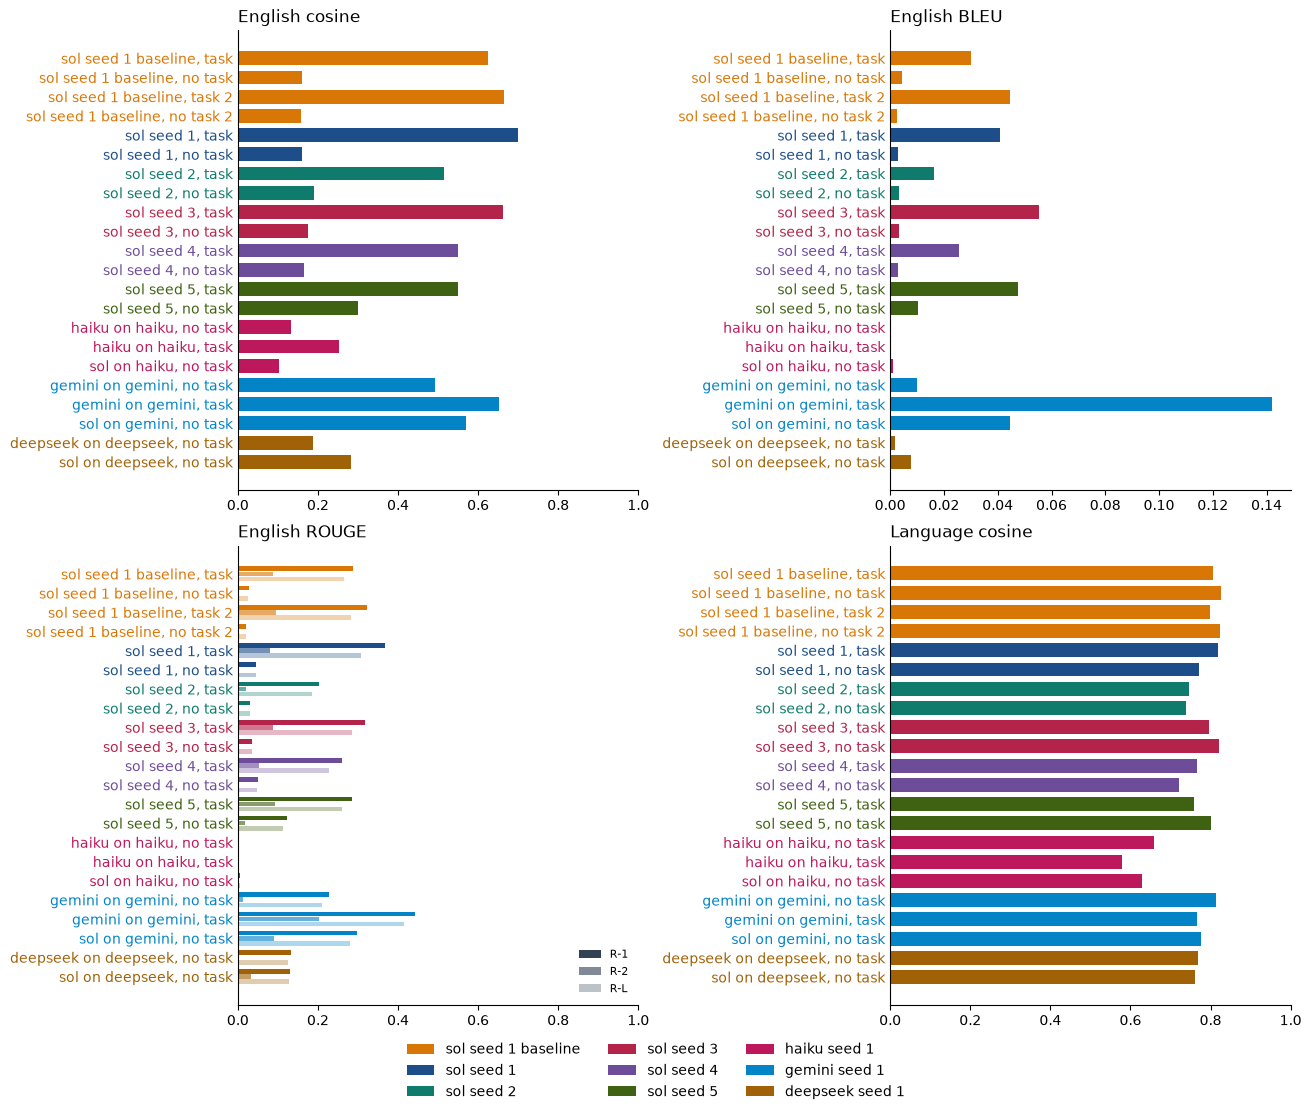

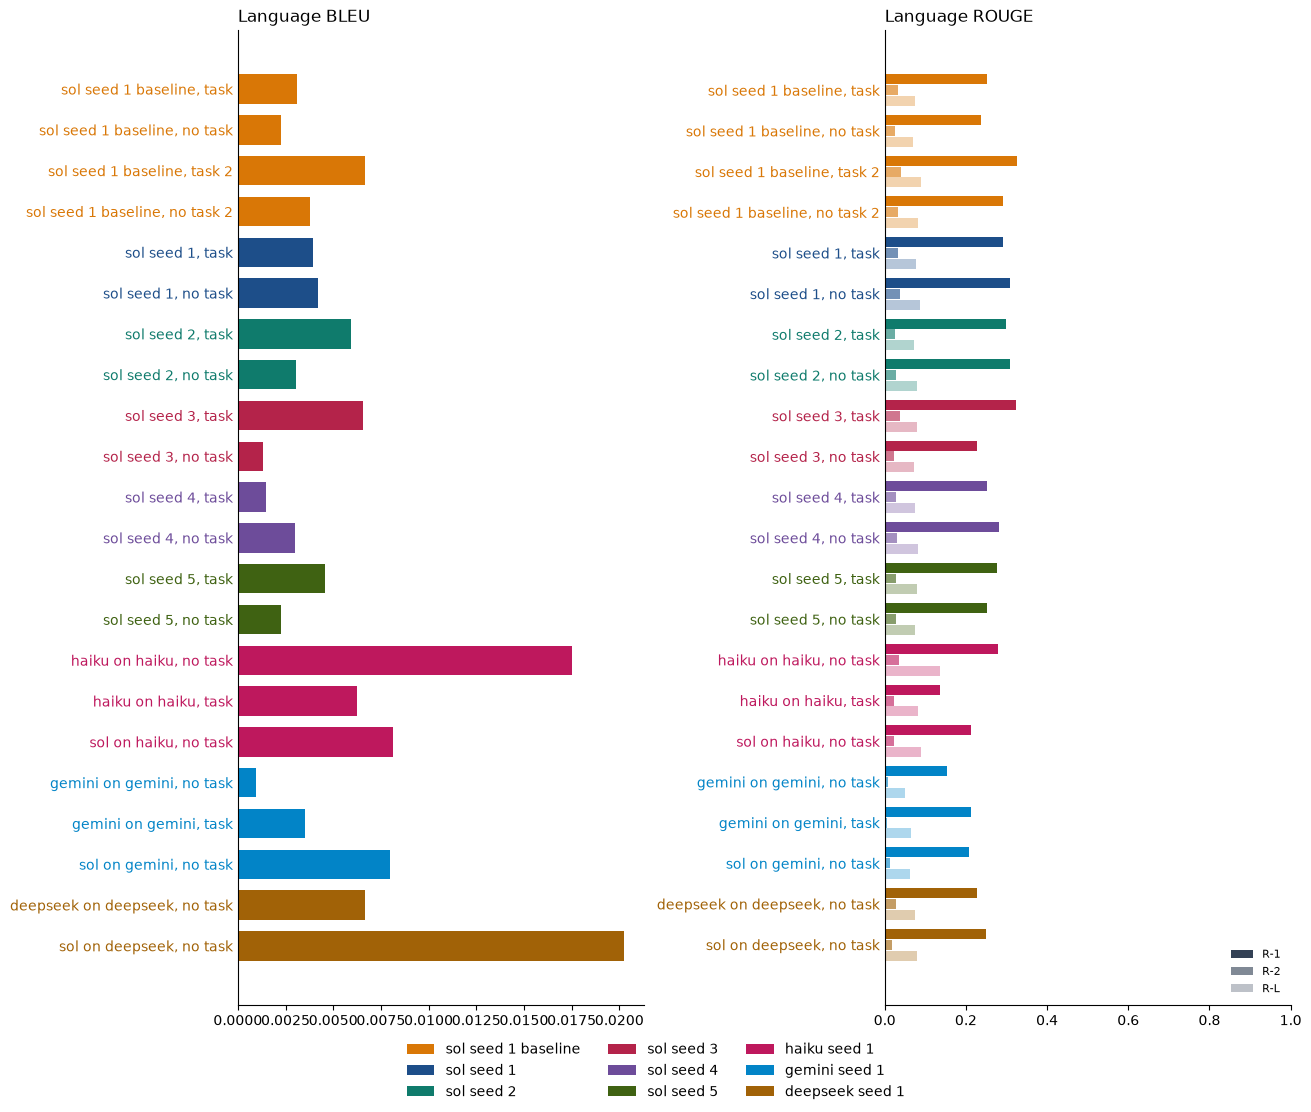

In [23]:
english = [report["english_transcript"] for report in scored]
language = [report["language_document"] for report in scored]

figure, axes = plt.subplots(2, 2, figsize=chart_size(2), constrained_layout=True)
panel(axes[0, 0], [row["cosine"] for row in english], "English cosine", 1)
panel(axes[0, 1], [row["bleu"] for row in english], "English BLEU")
grouped(
    axes[1, 0],
    [
        ("R-1", [row["rouge1"] for row in english]),
        ("R-2", [row["rouge2"] for row in english]),
        ("R-L", [row["rougeL"] for row in english]),
    ],
    "English ROUGE",
    1,
)
panel(axes[1, 1], [row["cosine"] for row in language], "Language cosine", 1)
scenario_legend(figure)
plt.show()

figure, axes = plt.subplots(1, 2, figsize=chart_size(2), constrained_layout=True)
panel(axes[0], [row["bleu"] for row in language], "Language BLEU")
grouped(
    axes[1],
    [
        ("R-1", [row["rouge1"] for row in language]),
        ("R-2", [row["rouge2"] for row in language]),
        ("R-L", [row["rougeL"] for row in language]),
    ],
    "Language ROUGE",
    1,
)
scenario_legend(figure)
plt.show()


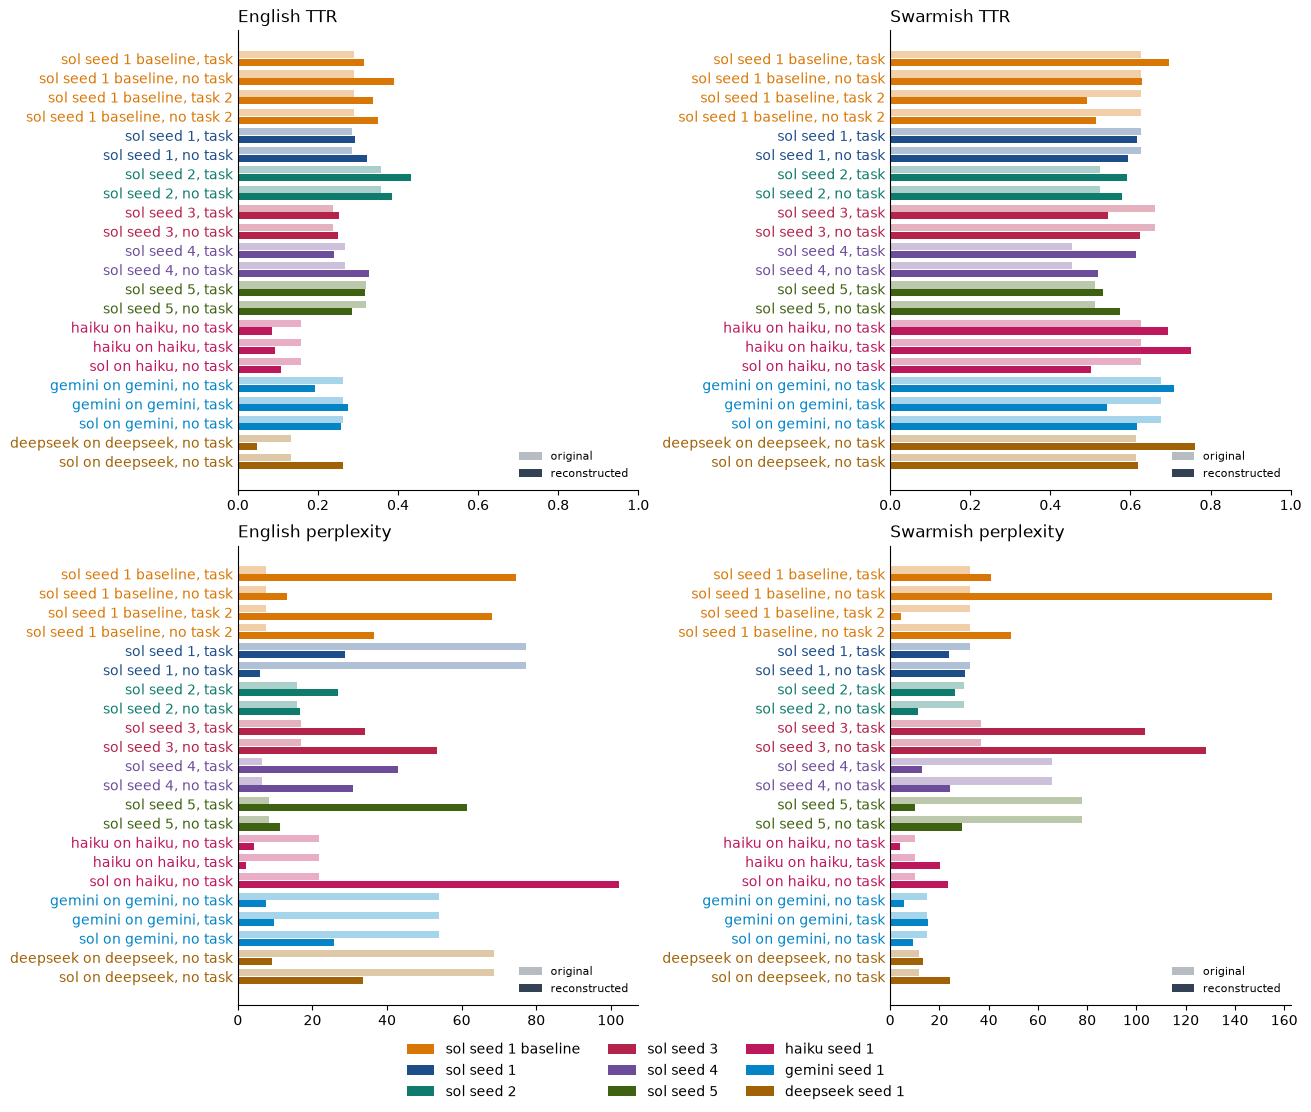

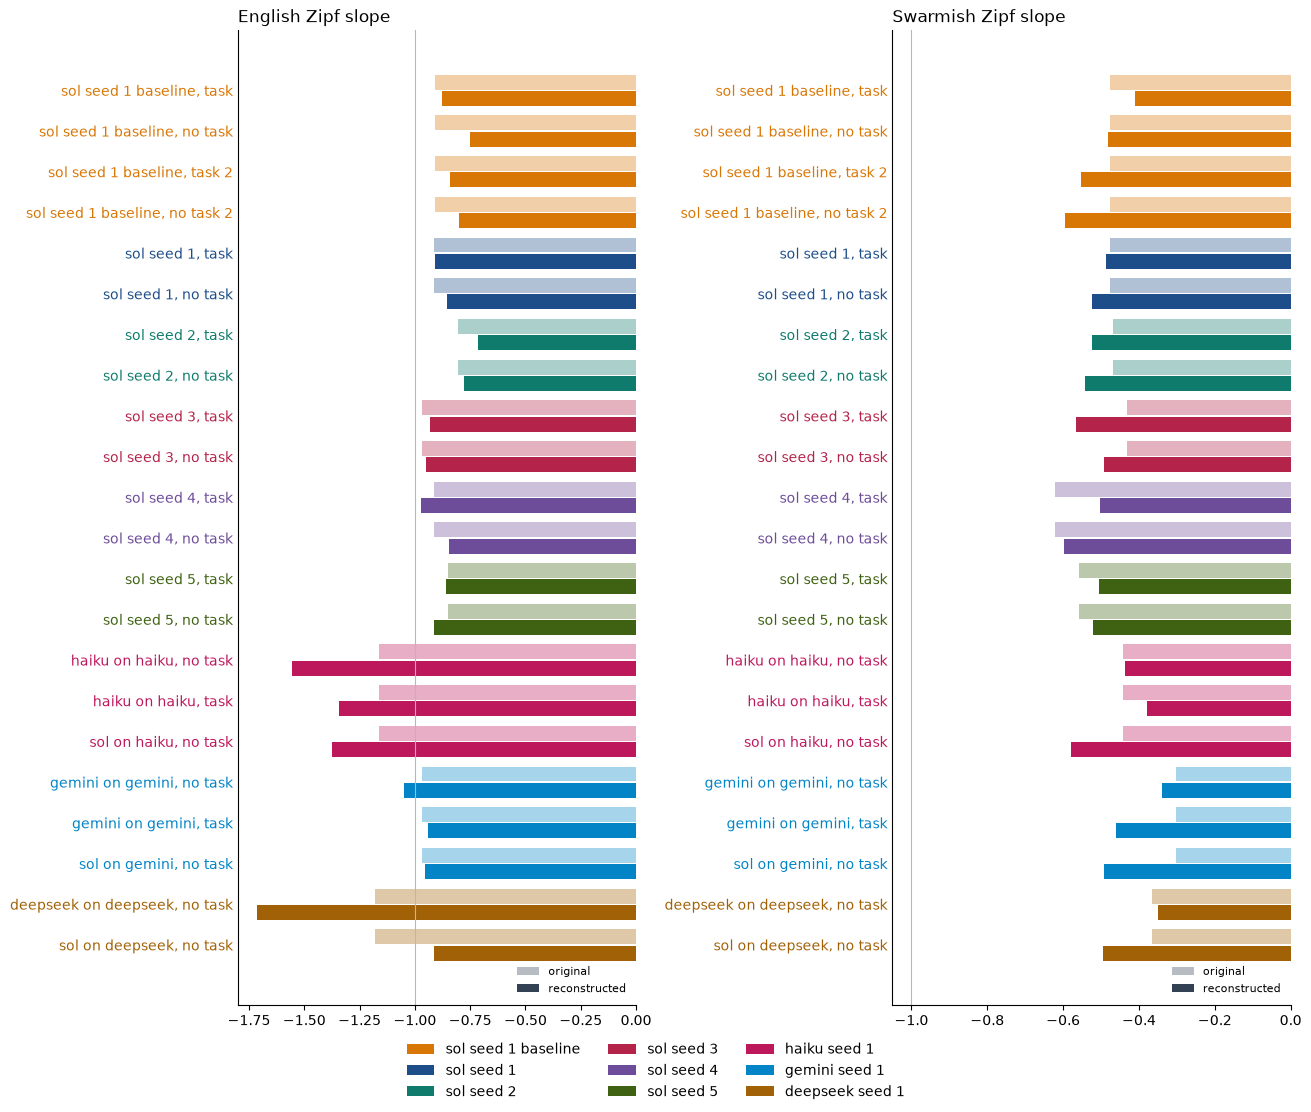

In [24]:
mono = [report["monolingual"] for report in scored]


def column(text, key):
    return [row[text][key] for row in mono]


figure, axes = plt.subplots(2, 2, figsize=chart_size(2), constrained_layout=True)
grouped(axes[0, 0], [("original", column("original_english", "ttr")), ("reconstructed", column("reconstructed_english", "ttr"))], "English TTR", 1)
grouped(axes[0, 1], [("original", column("original_swarmish", "ttr")), ("reconstructed", column("reconstructed_swarmish", "ttr"))], "Swarmish TTR", 1)
grouped(axes[1, 0], [("original", column("original_english", "bert_perplexity")), ("reconstructed", column("reconstructed_english", "bert_perplexity"))], "English perplexity")
grouped(axes[1, 1], [("original", column("original_swarmish", "bert_perplexity")), ("reconstructed", column("reconstructed_swarmish", "bert_perplexity"))], "Swarmish perplexity")
scenario_legend(figure)
plt.show()

figure, axes = plt.subplots(1, 2, figsize=chart_size(2), constrained_layout=True)
grouped(axes[0], [("original", column("original_english", "zipf_slope")), ("reconstructed", column("reconstructed_english", "zipf_slope"))], "English Zipf slope")
grouped(axes[1], [("original", column("original_swarmish", "zipf_slope")), ("reconstructed", column("reconstructed_swarmish", "zipf_slope"))], "Swarmish Zipf slope")
for axis in axes:
    axis.axvline(-1, color="#b0b8c4", linewidth=0.8)
scenario_legend(figure)
plt.show()


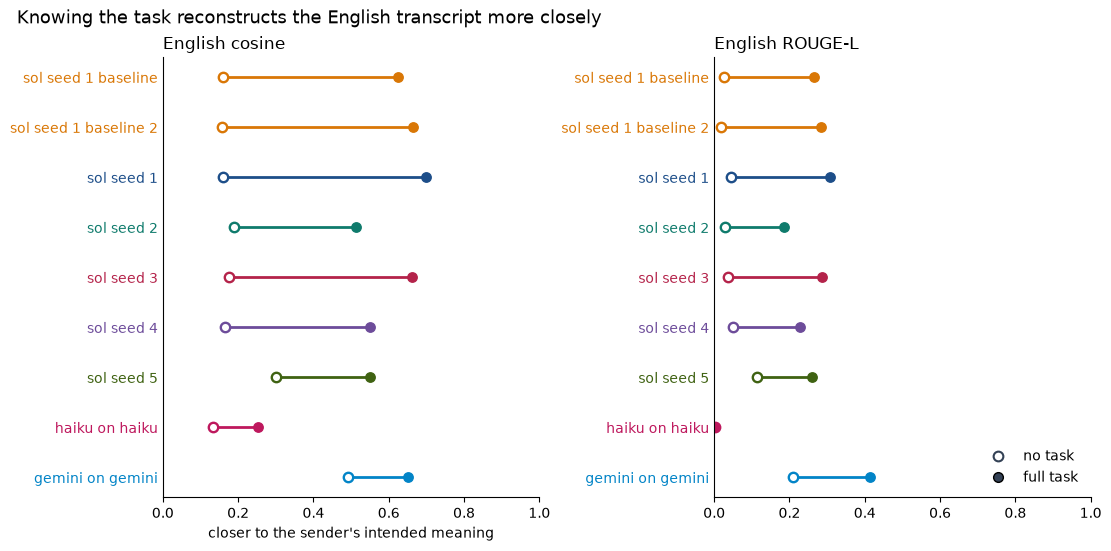

In [25]:
from matplotlib.lines import Line2D

def briefing(report):
    summary = json.loads((ROOT / report["monitor_dir"] / "monitor_summary.json").read_text())
    return "task" if summary["conditions_requested"] == ["task_full"] else "no task"


def stem(report):
    name = run_name(report)
    if name.endswith(", no task"):
        return name[:-len(", no task")]
    return name[:-len(", task")]


buckets = {}
for report in scored:
    buckets.setdefault((report["playthrough"], stem(report)), {"task": [], "no task": []})
    buckets[(report["playthrough"], stem(report))][briefing(report)].append(report)

paired = []
for playthrough, name in sorted(buckets, key=lambda key: (ORDER.index(key[0]), key[1])):
    sides = buckets[(playthrough, name)]
    if not sides["task"] or not sides["no task"]:
        continue
    task_runs = sorted(sides["task"], key=lambda report: report["monitor_dir"])
    no_runs = sorted(sides["no task"], key=lambda report: report["monitor_dir"])
    for index, (task_run, no_run) in enumerate(zip(task_runs, no_runs), start=1):
        paired.append({
            "label": name if index == 1 else f"{name} {index}",
            "color": SCENARIOS[playthrough][1],
            "task": task_run,
            "no": no_run,
        })

figure, axes = plt.subplots(1, 2, figsize=(11, 5.4), constrained_layout=True)
for ax, metric, title in ((axes[0], "cosine", "English cosine"), (axes[1], "rougeL", "English ROUGE-L")):
    for y, row in enumerate(paired):
        no_value = row["no"]["english_transcript"][metric]
        task_value = row["task"]["english_transcript"][metric]
        ax.plot([no_value, task_value], [y, y], color=row["color"], linewidth=2, zorder=1)
        ax.scatter([no_value], [y], s=46, facecolor="white", edgecolor=row["color"], linewidth=1.7, zorder=2)
        ax.scatter([task_value], [y], s=46, color=row["color"], zorder=2)
    ax.set_yticks(range(len(paired)), [row["label"] for row in paired])
    ax.invert_yaxis()
    ax.set_xlim(0, 1)
    ax.set_title(title, loc="left")
    ax.tick_params(axis="y", length=0)
    for tick, row in zip(ax.get_yticklabels(), paired):
        tick.set_color(row["color"])
axes[0].set_xlabel("closer to the sender's intended meaning")
axes[1].legend(
    handles=[
        Line2D([0], [0], marker="o", color="none", markerfacecolor="white", markeredgecolor="#334155", markeredgewidth=1.5, markersize=7, label="no task"),
        Line2D([0], [0], marker="o", color="none", markerfacecolor="#334155", markersize=7, label="full task"),
    ],
    frameon=False,
    loc="lower right",
)
figure.suptitle("Knowing the task reconstructs the English transcript more closely", x=0.01, ha="left", fontsize=13)
plt.show()


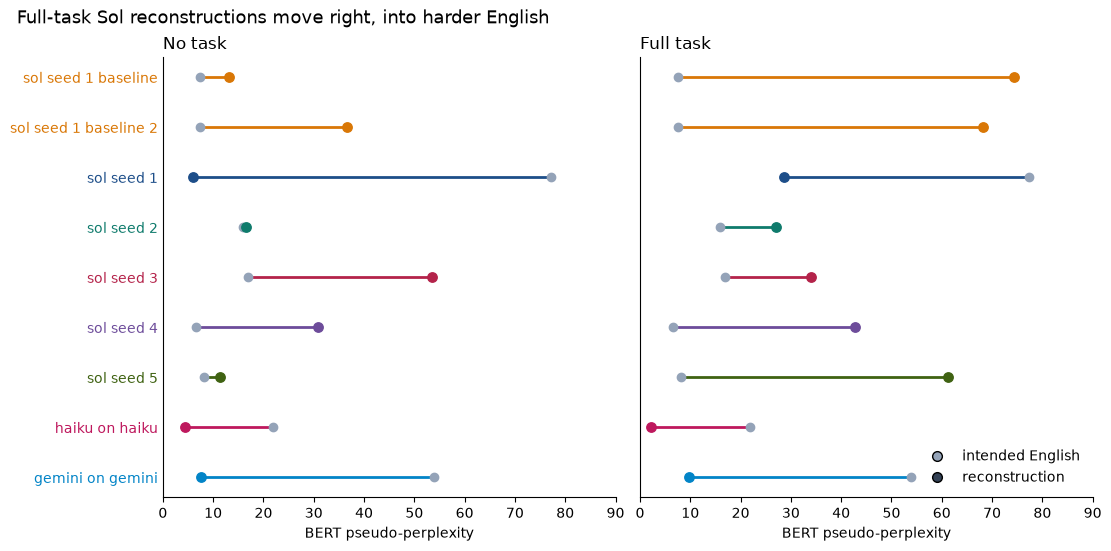

In [26]:
figure, axes = plt.subplots(1, 2, figsize=(11, 5.4), sharey=True, constrained_layout=True)
for ax, key, title in ((axes[0], "no", "No task"), (axes[1], "task", "Full task")):
    for y, row in enumerate(paired):
        original = row["task"]["monolingual"]["original_english"]["bert_perplexity"]
        reconstructed = row[key]["monolingual"]["reconstructed_english"]["bert_perplexity"]
        ax.plot([original, reconstructed], [y, y], color=row["color"], linewidth=2, zorder=1)
        ax.scatter([original], [y], s=36, color="#94a3b8", zorder=2)
        ax.scatter([reconstructed], [y], s=46, color=row["color"], zorder=3)
    ax.set_yticks(range(len(paired)), [row["label"] for row in paired])
    ax.set_xlim(0, 90)
    ax.set_title(title, loc="left")
    ax.set_xlabel("BERT pseudo-perplexity")
    ax.tick_params(axis="y", length=0)
    for tick, row in zip(ax.get_yticklabels(), paired):
        tick.set_color(row["color"])
axes[0].invert_yaxis()
axes[1].legend(
    handles=[
        Line2D([0], [0], marker="o", color="none", markerfacecolor="#94a3b8", markersize=7, label="intended English"),
        Line2D([0], [0], marker="o", color="none", markerfacecolor="#334155", markersize=7, label="reconstruction"),
    ],
    frameon=False,
    loc="lower right",
)
figure.suptitle("Full-task Sol reconstructions move right, into harder English", x=0.01, ha="left", fontsize=13)
plt.show()


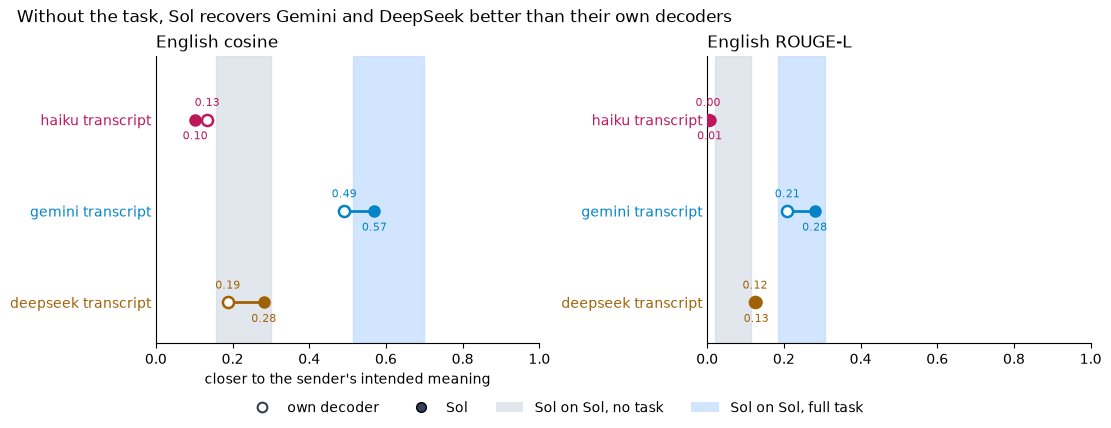

In [27]:
from matplotlib.lines import Line2D
from matplotlib.patches import Patch


def condition(report):
    summary = json.loads((ROOT / report["monitor_dir"] / "monitor_summary.json").read_text())
    task = summary["conditions_requested"] == ["task_full"]
    return task, decoder_name(summary["model"])


cross = []
for playthrough, language in SOURCE.items():
    own = sol = None
    for report in scored:
        if report["playthrough"] != playthrough:
            continue
        task, decoder = condition(report)
        if task:
            continue
        if decoder == language:
            own = report
        elif decoder == "sol":
            sol = report
    cross.append({"label": f"{language} transcript", "color": SCENARIOS[playthrough][1], "own": own, "sol": sol})

sol_runs = {"no task": [], "task": []}
for report in scored:
    if report["playthrough"] in SOURCE:
        continue
    task, decoder = condition(report)
    if decoder == "sol":
        sol_runs["task" if task else "no task"].append(report)

def mark(ax, value, y, text, color, above):
    ax.annotate(
        f"{value:.2f}",
        (value, y),
        textcoords="offset points",
        xytext=(0, 8 if above else -8),
        ha="center",
        va="bottom" if above else "top",
        fontsize=8,
        color=color,
    )


figure, axes = plt.subplots(1, 2, figsize=(11, 4.2), constrained_layout=True)
for ax, metric, title in ((axes[0], "cosine", "English cosine"), (axes[1], "rougeL", "English ROUGE-L")):
    no_values = [report["english_transcript"][metric] for report in sol_runs["no task"]]
    task_values = [report["english_transcript"][metric] for report in sol_runs["task"]]
    ax.axvspan(min(no_values), max(no_values), color="#cbd5e1", alpha=0.55, zorder=0)
    ax.axvspan(min(task_values), max(task_values), color="#bfdbfe", alpha=0.7, zorder=0)
    for y, row in enumerate(cross):
        own_value = row["own"]["english_transcript"][metric]
        sol_value = row["sol"]["english_transcript"][metric]
        ax.plot([own_value, sol_value], [y, y], color=row["color"], linewidth=2, zorder=1)
        ax.scatter([own_value], [y], s=64, facecolor="white", edgecolor=row["color"], linewidth=1.8, zorder=3)
        ax.scatter([sol_value], [y], s=64, color=row["color"], zorder=3)
        close = abs(own_value - sol_value) < 0.1
        mark(ax, own_value, y, own_value, row["color"], above=True)
        mark(ax, sol_value, y, sol_value, row["color"], above=not close)
    ax.set_yticks(range(len(cross)), [row["label"] for row in cross])
    ax.set_ylim(2.45, -0.7)
    ax.set_xlim(0, 1)
    ax.set_title(title, loc="left")
    ax.tick_params(axis="y", length=0)
    for tick, row in zip(ax.get_yticklabels(), cross):
        tick.set_color(row["color"])
axes[0].set_xlabel("closer to the sender's intended meaning")
figure.legend(
    handles=[
        Line2D([0], [0], marker="o", color="none", markerfacecolor="white", markeredgecolor="#334155", markeredgewidth=1.5, markersize=7, label="own decoder"),
        Line2D([0], [0], marker="o", color="none", markerfacecolor="#334155", markersize=7, label="Sol"),
        Patch(facecolor="#cbd5e1", alpha=0.55, label="Sol on Sol, no task"),
        Patch(facecolor="#bfdbfe", alpha=0.7, label="Sol on Sol, full task"),
    ],
    loc="outside lower center",
    ncol=4,
    frameon=False,
)
figure.suptitle("Without the task, Sol recovers Gemini and DeepSeek better than their own decoders", x=0.01, ha="left", fontsize=12)
plt.show()
